In [1]:
%load_ext autoreload
%autoreload 2

# DC4 Crab: time-integrated spectral analysis

Fit a point-source spectrum to the time-integrated, multienergy DC4 observation using the continuum detector response and the simulated background. This first analysis is phase-integrated and unpolarized; it does not separate the simulated nebula and pulsar components. The fitted model contains Crab and one free-normalization background component, so other sources and Galactic diffuse emission are not modeled explicitly. Interpret its results accordingly.


## Setup

Use the same configuration and paths as the Crab DataIO notebook. No time coordinate enters the likelihood.


In [2]:
from pathlib import Path
import sys

# Locate the workflow directory from the current notebook directory.
working_directory = Path.cwd().resolve()
candidates = [working_directory, *working_directory.parents]
workflow_dir = next(
    (directory for directory in candidates if (directory / "src" / "path_to_files.py").is_file()),
    None,
)
if workflow_dir is None and (working_directory / "workflow" / "src" / "path_to_files.py").is_file():
    workflow_dir = working_directory / "workflow"
if workflow_dir is None:
    raise FileNotFoundError("Start the notebook from the repository or workflow directory.")
if str(workflow_dir) not in sys.path:
    sys.path.insert(0, str(workflow_dir))

# Import the data, response, model, and fitting interfaces.
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astromodels import LinearPolarization, Model, PointSource, Powerlaw
from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import BinnedInstrumentResponse, BinnedThreeMLModelFolding, BinnedThreeMLPointSourceResponse
from cosipy.response import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from histpy import Histogram
from threeML import DataList, JointLikelihood
from src import path_to_files as paths

%matplotlib inline

In [3]:
# Import residual-analysis and plotting interfaces.
from src.residuals import ResidualAnalysis
from src.time_resolved_residuals_v1 import TemporalPredictionBuilder
from src.plot_residuals import PlottingResiduals


## Load the observation

Add the 14 weekly sparse histograms with their common time axis intact, including any overlapping weekly boundary bins. Project over time only after addition; the projected histogram contains the ten measured-energy bins.


In [4]:
# Load and combine all weekly time-resolved observations.
observed_temporal = None
for week in sorted(paths.weekly_paths):
    weekly_path = paths.data_dir_out / f"dc4_week_{week}_crab_continuum_binned.hdf5"
    weekly_data = BinnedData(paths.config_continuum_path)
    weekly_data.load_binned_data_from_hdf5(binned_data=str(weekly_path))
    weekly_histogram = weekly_data.binned_data
    if observed_temporal is None:
        observed_temporal = weekly_histogram.copy()
    else:
        observed_temporal = observed_temporal + weekly_histogram

# Sum the time axis while retaining the measured-energy and CDS axes.
observed_integrated = observed_temporal.project("Em", "Phi", "PsiChi").to_dense(copy=False)


## Load the simulated background

Project the background over the same full time range. It is a provisional background template, not a Crab fit. The DC4 simulation may share background events with the observation; some events were reported outside the binning range and their number has not yet been established.


In [5]:
# Load the time-resolved simulated background created by DataIO.
background_path = paths.data_dir_out / "simulated_background_crab_continuum_binned.hdf5"
background_temporal = Histogram.open(background_path)

# Sum the time axis to obtain the template used by the integrated fit.
background_integrated = background_temporal.project("Em", "Phi", "PsiChi").to_dense(copy=True)


In [6]:
# Compare the observed and simulated-background measured-energy distributions.
energy_edges = observed_integrated.axes["Em"].edges.to_value(u.keV)
observed_energy = np.asarray(observed_integrated.project("Em").contents)
background_energy = np.asarray(background_integrated.project("Em").contents)

## Define the Crab model

Use a fixed Crab position and a single power law with free normalization and index. Coordinates and starting spectral parameters follow the installed COSIpy Crab response example; they are starting assumptions, not fitted DC4 results. Zero polarization is fixed for this first analysis.


In [7]:
# Set the fixed Crab coordinates from the COSIpy response example.
crab_position = SkyCoord(ra=83.6330 * u.deg, dec=22.0144 * u.deg, frame="icrs")

# Set initial spectral parameters; the likelihood will fit K and index.
crab_spectrum = Powerlaw()
crab_spectrum.K.unit = 1 / (u.keV * u.cm**2 * u.s)
crab_spectrum.K.value = 1e-3
crab_spectrum.K.free = True
crab_spectrum.piv.unit = u.keV
crab_spectrum.piv.value = 100.0
crab_spectrum.piv.free = False
crab_spectrum.index.value = -2.0
crab_spectrum.index.free = True

# Use one fixed, unpolarized point source for the phase-integrated fit.
crab_polarization = LinearPolarization(degree=0.0, angle=0.0)
crab_polarization.degree.free = False
crab_polarization.angle.free = False
crab_source = PointSource(
    "Crab",
    ra=crab_position.ra.deg,
    dec=crab_position.dec.deg,
    spectral_shape=crab_spectrum,
    polarization=crab_polarization,
)
crab_source.position.ra.free = False
crab_source.position.dec.free = False
crab_model = Model(crab_source)
crab_model.display(complete=True)

Model summary:
==============

                  N
Point sources     1
Extended sources  0
Particle sources  0

Free parameters (2):
--------------------

                                   value min_value max_value            unit
Crab.spectrum.main.Powerlaw.K      0.001       0.0    1000.0  keV-1 s-1 cm-2
Crab.spectrum.main.Powerlaw.index   -2.0     -10.0      10.0                

Fixed parameters (5):
---------------------

                                          value min_value max_value unit
Crab.position.ra                         83.633       0.0     360.0  deg
Crab.position.dec                       22.0144     -90.0      90.0  deg
Crab.spectrum.main.Powerlaw.piv           100.0      None      None  keV
Crab.spectrum.main.polarization.degree      0.0       0.0     100.0     
Crab.spectrum.main.polarization.angle       0.0       0.0     180.0  deg

Properties (0):
--------------------

(none)


Linked parameters (0):
----------------------

(none)

Independent variables:
----------------------

(none)

Linked functions (0):
----------------------

(none)

## Build the response and likelihood

COSIpy uses the spacecraft history to calculate a point-source response in the coordinate frame of the data. This calculation can take time.


In [8]:
# Wrap the observed CDS and open the observing history and continuum response.
crab_data = EmCDSBinnedData(observed_integrated)
spacecraft_history = SpacecraftHistory.open(paths.data_ori_path)
detector_response = FullDetectorResponse.open(paths.data_responsecon_path)
instrument_response = BinnedInstrumentResponse(detector_response, crab_data)

# Build the point-source response for the observed Galactic CDS frame.
point_response = BinnedThreeMLPointSourceResponse(
    data=crab_data,
    instrument_response=instrument_response,
    sc_history=spacecraft_history,
    energy_axis=detector_response.axes["Ei"],
    nside=2 * crab_data.axes["PsiChi"].nside,
)
model_folding = BinnedThreeMLModelFolding(
    data=crab_data,
    point_source_response=point_response,
)
model_folding.set_model(crab_model)


The simulated background provides one common shape with one fitted normalization across all measured-energy bins.


In [9]:
# Copy the template because FreeNormBinnedBackground normalizes it in place.
background_distribution = {"background": background_integrated.copy()}
background_distribution["background"] += sys.float_info.min
background_model = FreeNormBinnedBackground(
    background_distribution,
    sc_history=spacecraft_history,
    copy=False,
)

# Initialize the background rate from the simulation and observing livetime.
background_rate = (
    float(np.asarray(background_integrated.contents).sum())
    / spacecraft_history.cumulative_livetime()
).to(u.Hz)
background_model.set_norm({"background": background_rate})

# Connect the source and background expectations to the integrated likelihood.
poisson_likelihood = PoissonLikelihood(data=crab_data, response=model_folding, bkg=background_model)
cosi_plugin = ThreeMLPluginInterface(
    name="cosi_crab", likelihood=poisson_likelihood, response=model_folding, bkg=background_model,
)
cosi_plugin.bkg_parameter["background"].min_value = 0.0
crab_likelihood = JointLikelihood(crab_model, DataList(cosi_plugin), verbose=False)


## Fit the integrated model

The optimizer estimates the power-law parameters and the background normalization from the observed CDS counts. Inspect fit convergence and warnings before interpreting or saving results.


In [10]:
# Fit the time-integrated observation and display the optimizer results.
crab_likelihood.fit()
crab_fit_results = crab_likelihood.results
crab_fit_results.display()

Best fit values:

,result,unit
parameter,,
Crab.spectrum.main.Powerlaw.K,(8.30 +/- 0.04) x 10^-4,1 / (keV s cm2)
Crab.spectrum.main.Powerlaw.index,-2.794 +/- 0.005,
background,(2.71220 +/- 0.00028) x 10,Hz


Correlation matrix:

1.00,-0.72,-0.27
-0.72,1.00,-0.24
-0.27,-0.24,1.00


Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi_crab,-1172950351.7431698
total,-1172950351.7431698


... (6 outputs left out)

Values of -log(likelihood) at the minimum:

,-log(likelihood)
cosi_crab,-1172950351.7431698
total,-1172950351.7431698


Values of statistical measures:

,statistical measures
AIC,-2345900697.4862356
BIC,-2345900666.443623


## Evaluate the fitted expectation

Evaluate the fitted source and background in the same measured-energy and CDS bins as the observation. These are real fit products only after the fit above completes successfully.


In [11]:
# Evaluate the fitted source and background contributions.
source_expectation = model_folding.expectation(copy=True)
background_expectation = background_model.expectation(copy=True)
total_expectation = source_expectation + background_expectation


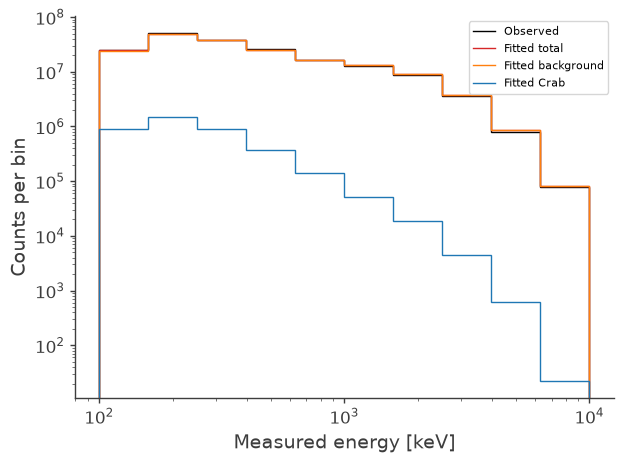

In [12]:
# Compare the fitted expectation and its components in measured energy.
source_energy = np.asarray(source_expectation.project("Em").contents)
fitted_background_energy = np.asarray(background_expectation.project("Em").contents)
total_energy = np.asarray(total_expectation.project("Em").contents)

fig, ax = plt.subplots()
ax.stairs(observed_energy, energy_edges, label="Observed", color="black")
ax.stairs(total_energy, energy_edges, label="Fitted total", color="tab:red")
ax.stairs(fitted_background_energy, energy_edges, label="Fitted background", color="tab:orange")
ax.stairs(source_energy, energy_edges, label="Fitted Crab", color="tab:blue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(xlabel="Measured energy [keV]", ylabel="Counts per bin")
ax.legend()
fig.tight_layout()
plt.show()

## Integrated multienergy residuals

Compare the observed counts with the fitted Crab plus background expectation. The residuals use projected counts: `raw` is D − M, `pearson` is (D − M)/√M, and `fractional` is (D − M)/M. Normalized residuals require positive expected counts. Shared simulated background and omitted sky components affect interpretation; nominal Poisson or Gaussian references are not calibrated goodness-of-fit tests.


In [13]:
# Prepare residuals from the in-memory observation and fitted expectation.
crab_residuals = ResidualAnalysis(
    observed=observed_integrated,
    expected=total_expectation,
)
crab_plotter = PlottingResiduals(crab_residuals)


Observed data have no time information; using atemporal residual analysis.


### Residuals versus measured energy

`Em_projection` sums the angular coordinates and preserves each measured-energy bin. The examples show raw and fractional residuals; `residual_type="pearson"` is also available. The fractional residual is undefined where the projected expectation is zero.


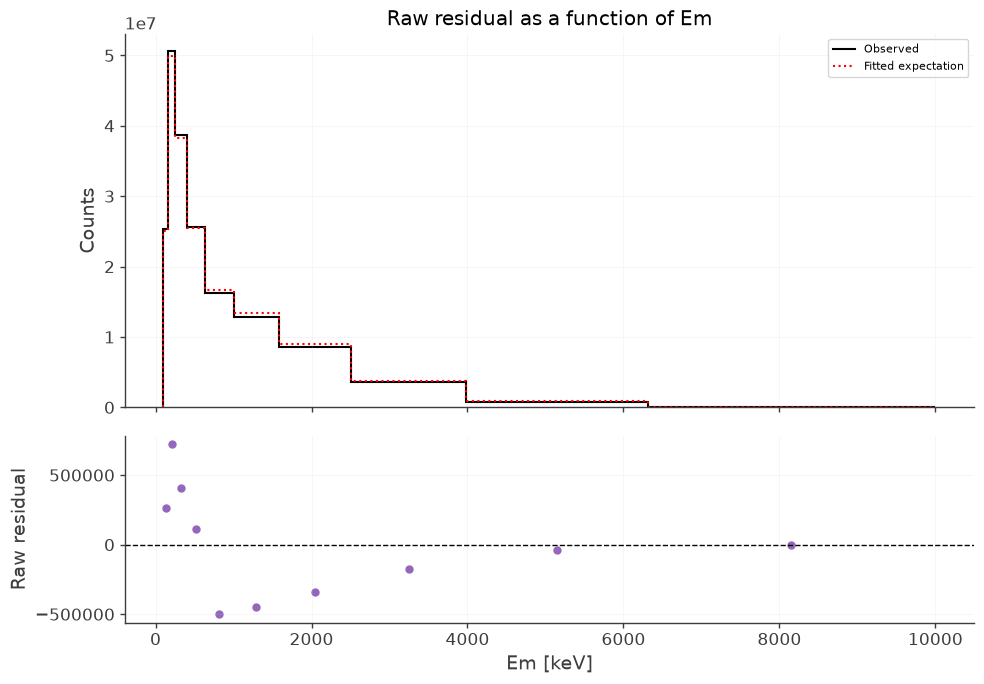

In [14]:
# Compare observed and fitted counts and their difference per energy bin.
crab_energy_raw_figure = crab_plotter.plot(
    "Em_projection",
    residual_type="raw",
    show_uncertainty=False,
)


### Angular map for one energy bin

`Em_PsiChi_projection` selects a measured-energy bin by its zero-based index. Change `energy_bin_index` to inspect another bin without repeating the fit. Here `pearson` scales the count difference by the square root of the expectation.


Selected measured-energy interval [keV]: [398.107 630.957]


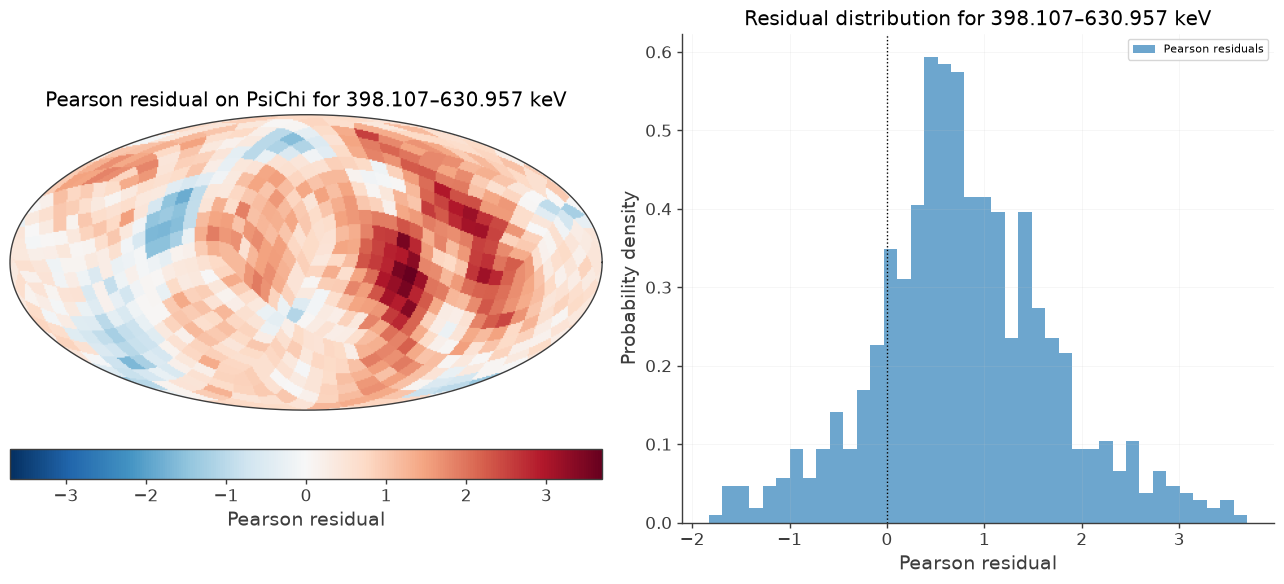

In [15]:
# Select one measured-energy bin for the PsiChi map.
energy_bin_index = 3
print("Selected measured-energy interval [keV]:", energy_edges[energy_bin_index:energy_bin_index + 2])
crab_energy_psichi_figure = crab_plotter.plot(
    "Em_PsiChi_projection",
    residual_type="pearson",
    energy_bin_index=energy_bin_index,
    show_gaussian_reference=False,
)


## Temporal residual analysis

Build physical temporal predictions from the integrated fit, then pass the matching observed and expected histograms to the same residual-analysis interface.


### Build one physical time interval

The fitted point-source model is folded with the continuum response and the orientation of the selected interval. The simulated background from the same interval is scaled using the integrated fitted background. The class returns the observed counts and the total expectation; it does not expose the individual components through this method.

In [16]:
# Configure the temporal class with the integrated fit.
crab_temporal_analysis = TemporalPredictionBuilder(
    observed=observed_temporal, integrated_expected=total_expectation
)

crab_temporal_analysis.configure_physical_model(
    fitted_sky=crab_fit_results.optimized_model,
    response_path=paths.data_responsecon_path,
    orientation=spacecraft_history,
    temporal_background=background_temporal,
    fitted_background=background_expectation,
    fitted_energy_axis=detector_response.axes["Ei"],
    earth_occ=True,
)


In [17]:
# Build one original time interval, retaining all measured-energy bins.
crab_time_bin_index = 13
crab_observed_interval, crab_expected_interval = crab_temporal_analysis.build_physical_time_range(
    start=crab_time_bin_index, stop=crab_time_bin_index + 1
)


### Residuals for the selected interval

Select the returned interval and project its observed and expected counts onto measured energy. The plot is descriptive and does not request an uncertainty or Gaussian reference.


In [18]:
# Prepare residuals from the matching temporal observation and expectation.
crab_temporal_residuals = ResidualAnalysis(
    observed=crab_observed_interval, expected=crab_expected_interval
)
# Select the only returned time bin for energy and angular projections.
crab_interval_residuals = crab_temporal_residuals.select_time_bin(0)
crab_interval_plotter = PlottingResiduals(crab_interval_residuals)


Observed data contain time information; using temporal residual analysis.


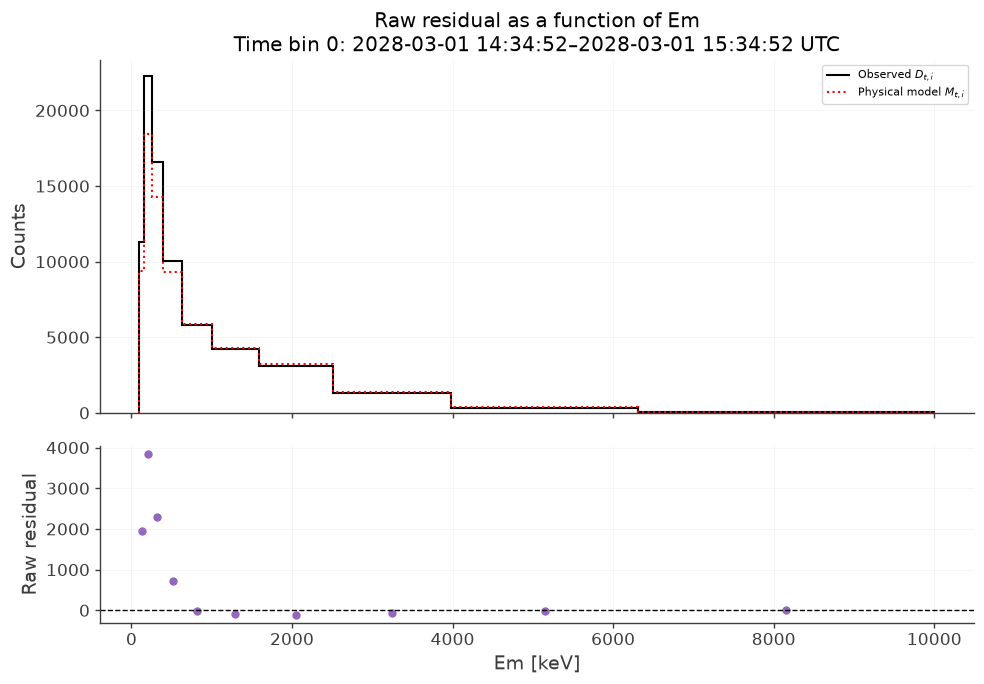

In [19]:
# Compare observed and expected counts and raw residuals in energy.
crab_interval_energy_raw = crab_interval_plotter.plot(
    "Em_projection", residual_type="raw", show_uncertainty=False
)


### Explore consecutive time intervals

Build five native intervals and project the resulting residuals onto time. The first prediction is reused from the class cache.


In [20]:
# Build consecutive intervals while keeping all measured-energy bins.
crab_time_start = crab_time_bin_index
crab_time_stop = crab_time_start + 5
crab_observed_series, crab_expected_series = crab_temporal_analysis.build_physical_time_range(
    start=crab_time_start, stop=crab_time_stop
)


Observed data contain time information; using temporal residual analysis.


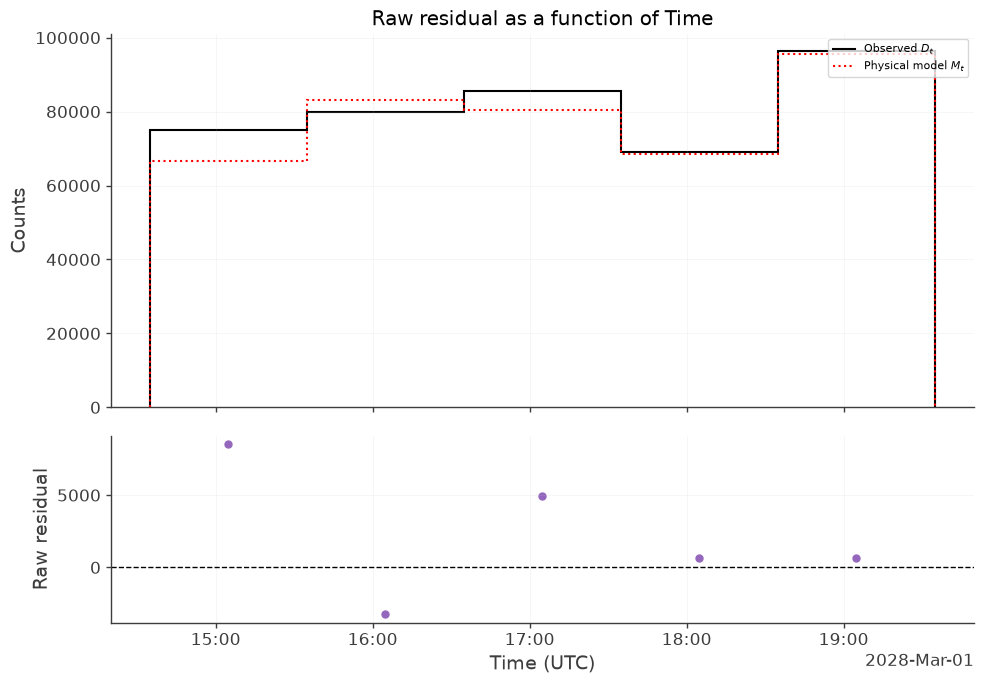

In [21]:
# Prepare and plot raw residuals after projection onto Time.
crab_series_residuals = ResidualAnalysis(
    observed=crab_observed_series, expected=crab_expected_series
)
crab_series_plotter = PlottingResiduals(crab_series_residuals)
crab_time_raw = crab_series_plotter.plot(
    "Time_projection", residual_type="raw", show_uncertainty=False
)
